In [2]:
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')

### Alameda County Jury Panels ###

In [5]:
# Ethnicity: Juror's self-reported ethnicity
# Eligible: Percent of Alemeda County residents (eligible for jury duty) identifying as each ethnicity
# Panels: Percent of jurors identifying as each ethnicity (1453 jurors in total)
jury = Table().with_columns(
    'Ethnicity', make_array('Asian', 'Black', 'Latino', 'White', 'Other'),
    'Eligible', make_array(0.15, 0.18, 0.12, 0.54, 0.01),
    'Panels', make_array(0.26, 0.08, 0.08, 0.54, 0.04)
)

jury

Ethnicity,Eligible,Panels
Asian,0.15,0.26
Black,0.18,0.08
Latino,0.12,0.08
White,0.54,0.54
Other,0.01,0.04


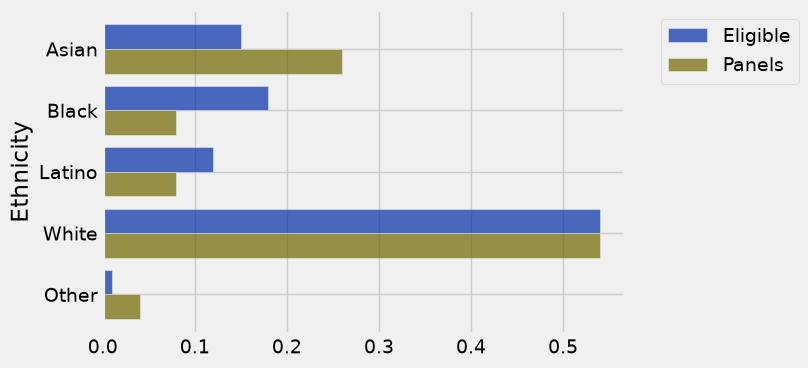

In [6]:
jury.barh('Ethnicity')

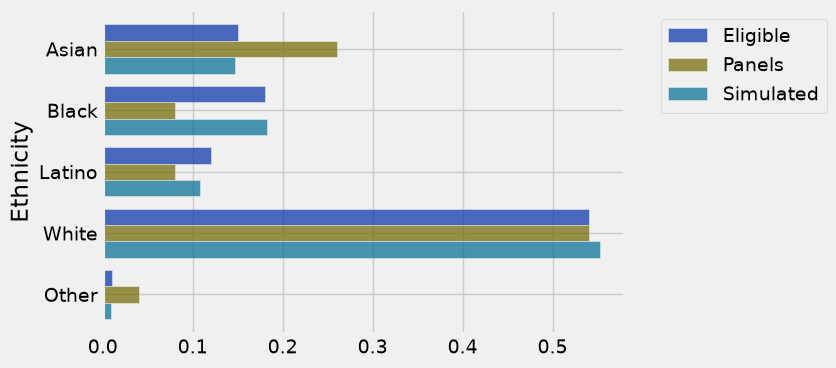

In [23]:
ethnicity_prop = make_array(0.15, 0.18, 0.12, 0.54, 0.01)
simulated_jurors = sample_proportions(1453, ethnicity_prop)
jury_with_simulated = jury.with_column('Simulated', simulated_jurors)
jury_with_simulated.barh('Ethnicity')

#### Distance Between Distributions

In [24]:
# Difference between "eligible" distribution and "panels" distribution
diffs = jury.column('Panels') - jury.column('Eligible')
jury_with_difference = jury.with_column('Difference', diffs)
jury_with_difference

Ethnicity,Eligible,Panels,Difference
Asian,0.15,0.26,0.11
Black,0.18,0.08,-0.1
Latino,0.12,0.08,-0.04
White,0.54,0.54,0
Other,0.01,0.04,0.03


In [20]:
# Not a great overall statistic, since the differences always sum to 0
sum(diffs)

2.7755575615628914e-17

#### Total Variation Distance

Total variation distance is defined to be the sum of the *absolute values* of the differences divided by 2.

### Practice ###

Write a function that takes two arrays as inputs (representing two different distributions) and returns the total variation distance between them.

In [ ]:
def tvd(distribution1, distribution2):
...

In [11]:
# The TVD of our observed data (Panels) from their expected values
# assuming the model is true (Eligbible)
obsvd_tvd = tvd(jury.column('Panels'), jury.column('Eligible'))
obsvd_tvd

0.14000000000000001

In [33]:
# You can ues sample_proportions to simulate a categorical distribution with as many categories as you like.
ethnicity_prop = make_array(0.15, 0.18, 0.12, 0.54, 0.01)
simulated_jurors = sample_proportions(1453, ethnicity_prop)
simulated_jurors

array([ 0.13764625,  0.18857536,  0.12801101,  0.53613214,  0.00963524])

### Practice ###

Write a function that returns the TVD between a simulated jury and the "eligible" distribution.
Afterward, generate 10,000 simulated TVDs and visualize the distribution.

In [ ]:
def simulated_tvd():
    ...